### Step 1: Import the Tools We Need
Before we can work with the data, we load a few ready-made libraries (code that other people already wrote for us):
- **numpy** – helps with number-crunching and math operations.
- **pandas** – lets us load and work with the data as a table (like an Excel sheet).
- **seaborn** and **matplotlib** – used to draw charts and graphs so we can visually spot patterns in the data.
- **warnings** – the last two lines simply tell Python to hide harmless warning messages, so the notebook's output stays clean and easy to read.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

### Step 2: Load the Dataset
This line reads the file `Food_Delivery_Times.csv` — the spreadsheet containing all 1,000 past delivery records — and stores it in a variable called `df` (short for "DataFrame", which is just pandas' name for a table of data). From this point on, `df` is how we refer to our dataset.

In [2]:
df = pd.read_csv("Food_Delivery_Times.csv")

### Step 3: Peek at the First Few Rows
`df.head()` shows the first 5 rows of the dataset. This is a quick sanity check to confirm the file loaded correctly and to see what the columns and values actually look like before doing anything else with them.

In [3]:
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,29
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,74
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,31
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


### Step 4: Check for Missing Data
Real-world data is rarely perfectly complete. This code counts how many empty (missing) values exist in each column, before any cleaning is done. Knowing exactly where the gaps are tells us which columns need to be fixed in the next step.

In [4]:
print('Missing values before cleaning:')
display(df.isnull().sum())

Missing values before cleaning:


Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0
dtype: int64

### Step 5: List All Column Names
This simply prints out the names of every column in the dataset, giving us a clear list of exactly what information we're working with.

In [5]:
df.columns

Index(['Order_ID', 'Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day',
       'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs',
       'Delivery_Time_min'],
      dtype='object')

### Step 6: Clean the Data
This is where the missing values found earlier get fixed:
- For the three category columns — **Weather**, **Traffic_Level**, and **Time_of_Day** — every missing value is filled in with the **mode**, meaning the single most frequently occurring value in that column. This is a safe, low-risk guess for a missing category.
- For the **Courier_Experience_yrs** column (a number), missing values are filled with the **median** — the middle value of the column — instead of the average, because the median isn't thrown off by a few unusually high or low values.
- The **Order_ID** column is dropped completely, since it's just a random reference number for each delivery and has no real connection to how long a delivery actually takes.

Finally, the missing-value counts are printed again to confirm every gap has been filled.

In [6]:
# Fill null values for categorical columns with the mode
df['Weather'].fillna(df['Weather'].mode()[0], inplace=True)
df['Traffic_Level'].fillna(df['Traffic_Level'].mode()[0], inplace=True)
df['Time_of_Day'].fillna(df['Time_of_Day'].mode()[0], inplace=True)

# Fill null values for numerical column 'Courier_Experience_yrs' with the median
df['Courier_Experience_yrs'].fillna(df['Courier_Experience_yrs'].median(), inplace=True)

# Drop the 'Order_ID' column
df.drop('Order_ID', axis=1, inplace=True)

print('Missing values after cleaning:')
display(df.isnull().sum())

Missing values after cleaning:


Distance_km               0
Weather                   0
Traffic_Level             0
Time_of_Day               0
Vehicle_Type              0
Preparation_Time_min      0
Courier_Experience_yrs    0
Delivery_Time_min         0
dtype: int64

### Step 7: Confirm the Cleaning Worked
We look at the first few rows again after cleaning, to visually confirm the missing values are gone and that the `Order_ID` column has been removed.

In [7]:
df.head()

,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,7.93,Windy,Low,Afternoon,Scooter,12,1.0,29
1,16.42,Clear,Medium,Evening,Bike,20,2.0,74
2,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,31
4,19.03,Clear,Low,Morning,Bike,16,5.0,68


### Step 8: Descriptive Statistics of Numerical Features
`df.describe()` gives a quick statistical summary — count, average (mean), standard deviation, minimum, maximum, and the 25th/50th/75th percentiles — for every numeric column. This helps us understand the typical range and spread of values like distance, preparation time, and delivery time before doing any modeling.

In [8]:
display(df.describe())

,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,1000.000000,1000.000000,1000.000000,1000.00000
mean,10.059970,16.982000,4.592000,51.86100
std,5.696656,7.204553,2.871198,23.40255
min,0.590000,5.000000,0.000000,10.00000
25%,5.105000,11.000000,2.000000,34.00000
50%,10.190000,17.000000,5.000000,50.00000
75%,15.017500,23.000000,7.000000,66.00000
max,19.990000,29.000000,9.000000,135.00000


### Step 9: Distribution of the Target Variable (`Delivery_Time_min`)
This draws a histogram — a bar chart showing how often different delivery times occur — for our target variable, `Delivery_Time_min` (the value we're ultimately trying to predict). The smooth curve drawn over the bars (called a KDE, or Kernel Density Estimate) makes the overall shape of the distribution easier to see, helping us understand whether delivery times are evenly spread out, clustered together, or skewed toward one side.

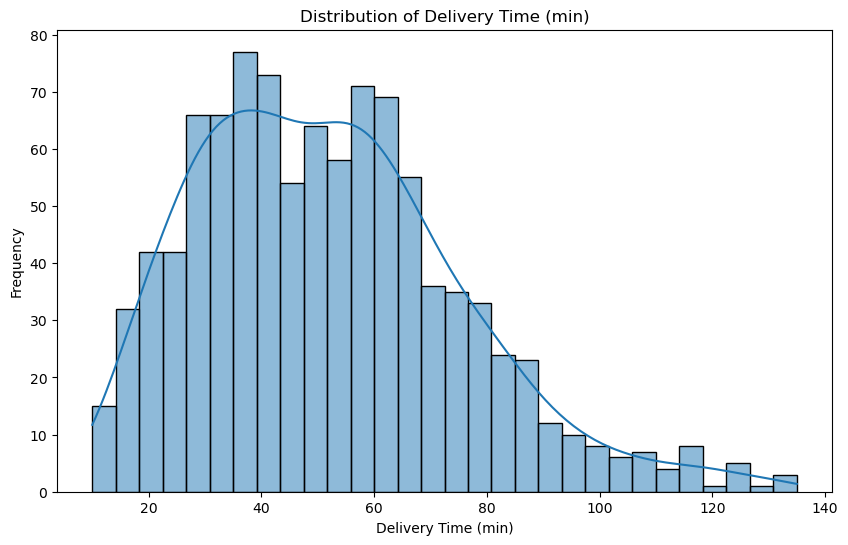

In [9]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Delivery_Time_min'], kde=True, bins=30)
plt.title('Distribution of Delivery Time (min)')
plt.xlabel('Delivery Time (min)')
plt.ylabel('Frequency')
plt.show()

**What we observed (Step 9 – Distribution of Delivery Time):**
- The average delivery takes about **52 minutes** (the median is 50), and the middle 50% of deliveries land between **34 and 66 minutes**.
- The curve has a longer tail on the right: a few orders take much longer (up to **135 minutes**), which pulls the average slightly above the median. Only 18 deliveries (1.8%) are unusually slow (over 114 minutes).
- There is no single sharp peak. Delivery times are spread over a wide range, which tells us that several factors are at work, so a good model needs to look at more than one of them.

### Step 10: Numeric Features vs. Delivery Time (Scatter Plots)
A scatter plot puts one dot on the chart for every delivery: the position left-to-right is the feature (distance or preparation time) and the position bottom-to-top is how long the delivery took. The red line is the overall trend (a best-fit straight line) running through the dots. If the dots rise along the line, the feature and the delivery time increase together. We draw one chart for `Distance_km` and one for `Preparation_Time_min`.

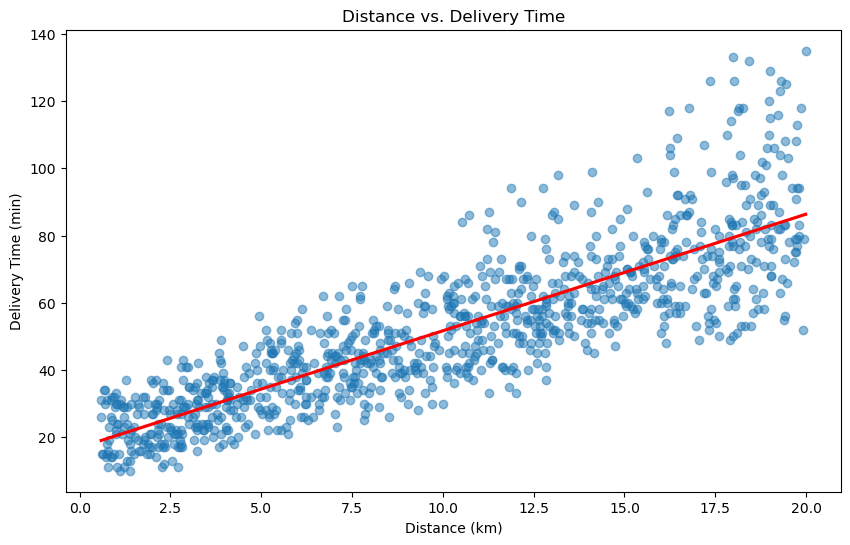

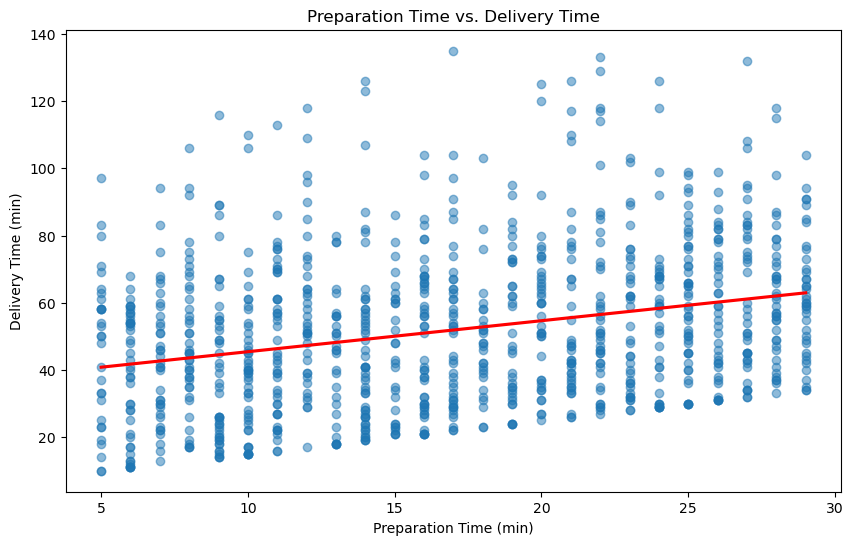

In [10]:
# (column, name shown in the title, axis label)
numeric_drivers = [
    ('Distance_km', 'Distance', 'Distance (km)'),
    ('Preparation_Time_min', 'Preparation Time', 'Preparation Time (min)'),
]

for col, name, axis_label in numeric_drivers:
    plt.figure(figsize=(10, 6))
    sns.regplot(x=col, y='Delivery_Time_min', data=df, ci=None,
                scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})
    plt.title(f'{name} vs. Delivery Time')
    plt.xlabel(axis_label)
    plt.ylabel('Delivery Time (min)')
    plt.show()

**What we observed (Step 10 – Scatter Plots):**
- **Distance vs. Delivery Time:** the dots rise steadily along a nearly straight line (correlation about **0.84**). Each extra kilometre adds roughly **3.5 minutes** on average: trips of 0–5 km average about 27 minutes, while trips of 15–20 km average about 79 minutes. The dots spread out more on long trips, so other factors (such as traffic and weather) also play a role there.
- **Preparation Time vs. Delivery Time:** the trend is upward but much weaker (correlation about **0.28**). Each extra minute in the kitchen adds only about **0.9 minutes** to the total, and the dots are widely scattered around the line. Orders prepared in 10 minutes or less average about 43 minutes, versus about 60 minutes when preparation took 23 minutes or more.
- Overall, distance is the main numeric driver; preparation time helps explain delivery time, but only partly.

**What we observed (Step 11 – Correlation Matrix):**
- `Distance_km` is the only strong link with `Delivery_Time_min` (**0.84**). `Preparation_Time_min` has a weak positive link (**0.28**), and `Courier_Experience_yrs` is essentially unrelated (**-0.04**).
- The three input columns are almost completely unrelated to each other (all values close to 0), so each one brings its own separate information to the model.
- This chart only covers numeric columns. The category columns are explored in the charts that follow.

### Step 12: Relationship Between Categorical Features and Delivery Time
For each category column (`Weather`, `Traffic_Level`, `Time_of_Day`, `Vehicle_Type`), this draws a box plot comparing delivery times across the different categories within that column (for example, "Rainy" vs "Clear" for Weather). A box plot shows the median, the middle 50% range, and any outliers for each group, making it easy to visually spot whether a particular category (like "High" traffic) tends to push delivery time up or down compared to the others.

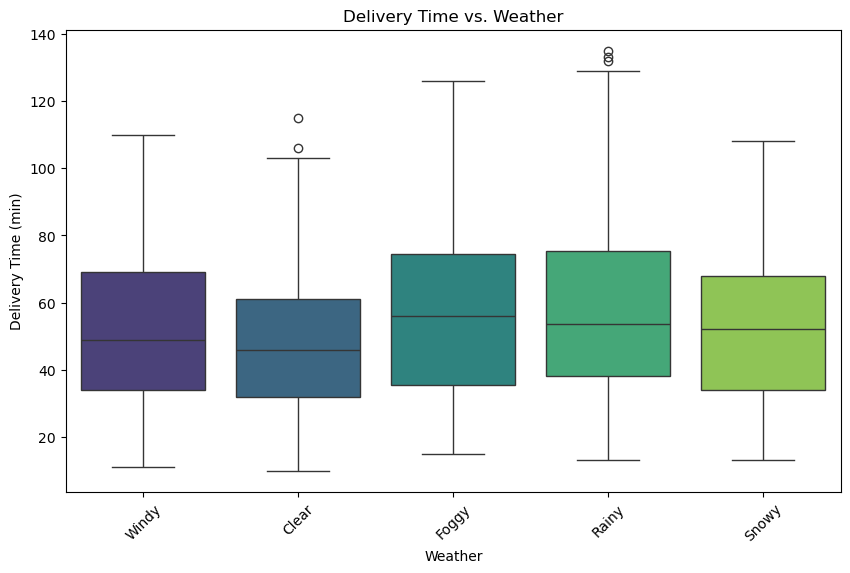

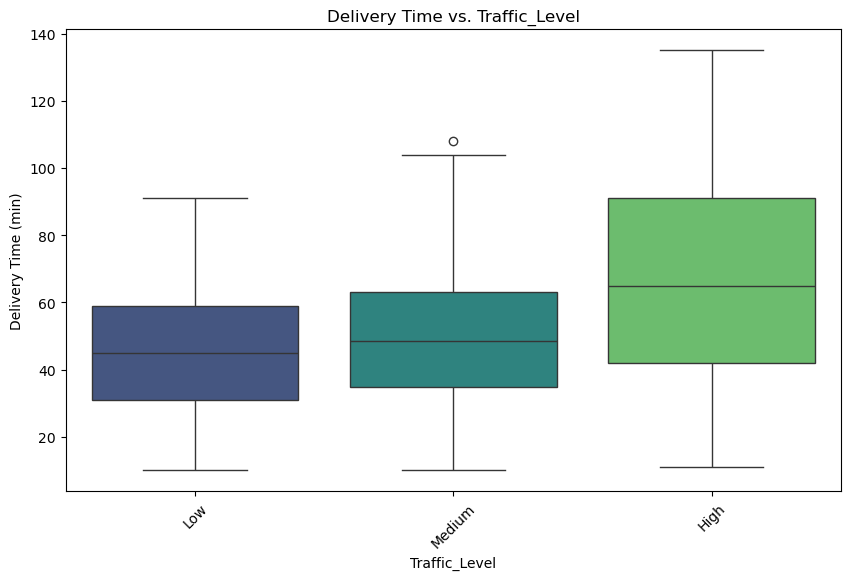

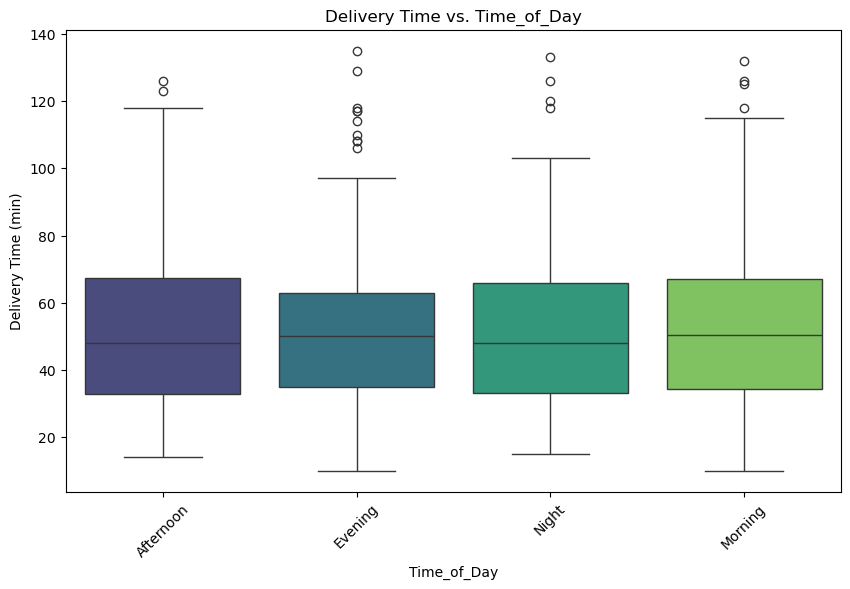

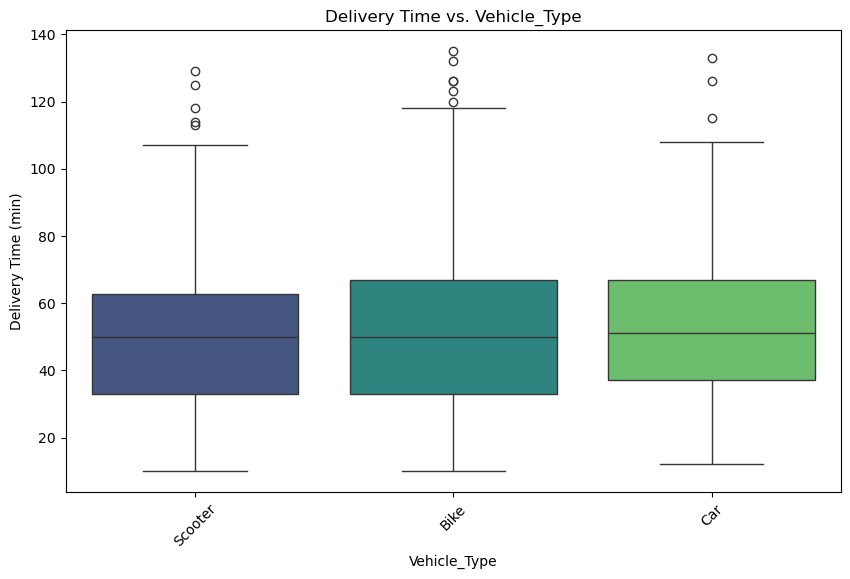

In [12]:
categorical_cols = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']

for col in categorical_cols:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=col, y='Delivery_Time_min', data=df, palette='viridis')
    plt.title(f'Delivery Time vs. {col}')
    plt.xlabel(col)
    plt.ylabel('Delivery Time (min)')
    plt.xticks(rotation=45)
    plt.show()

**What we observed (Step 12 – Box Plots):**
- **Traffic_Level:** delivery time steps up clearly with traffic. The median is about 45 minutes for Low, 49 for Medium and 65 for High. The High box is also much taller, meaning delivery times are far less predictable in heavy traffic.
- **Weather:** Clear weather has the lowest typical delivery time (median 46 minutes), while Foggy and Rainy weather are the slowest (medians of 56 and 54 minutes).
- **Time_of_Day** and **Vehicle_Type:** the boxes sit at almost the same height (medians of 48–51 minutes), so these two categories make little visible difference.

### Step 13: Which Categorical Factor Matters Most?
Here we put the four category columns side by side. For each one, we find the average delivery time of every group (for example Clear, Rainy, Foggy…), and then measure the **gap** between the slowest group and the fastest group. A bigger gap means that column has a bigger influence on delivery time.

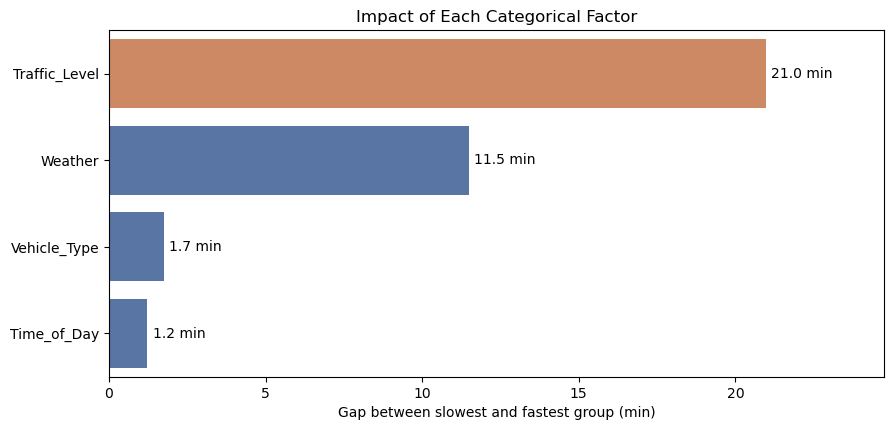

In [13]:
categorical_cols = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']

# Gap = average time of the slowest group minus average time of the fastest group
gaps = {}
for col in categorical_cols:
    group_means = df.groupby(col)['Delivery_Time_min'].mean()
    gaps[col] = group_means.max() - group_means.min()
gaps = pd.Series(gaps).sort_values(ascending=False)

plt.figure(figsize=(10, 4.5))
ax = sns.barplot(x=gaps.values, y=gaps.index, hue=gaps.index,
                 palette=['#DD8452'] + ['#4C72B0'] * (len(gaps) - 1), legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f min', padding=4)
plt.xlim(0, gaps.max() * 1.18)
plt.title('Impact of Each Categorical Factor')
plt.xlabel('Gap between slowest and fastest group (min)')
plt.ylabel('')
plt.show()

**What we observed (Step 13 – Ranking of Categorical Factors):**
- **Traffic_Level** matters most: the average delivery time differs by **21.0 minutes** between High traffic (slowest) and Low traffic (fastest).
- **Weather** comes second with a gap of **11.5 minutes** (Rainy is slowest, Clear is fastest).
- **Vehicle_Type (1.7 min)** and **Time_of_Day (1.2 min)** barely change the average delivery time.

### Step 14: Average Delivery Time by Category
This shows the same story group by group. Each bar is the average delivery time of one category, the slowest group is coloured orange, and the dashed line marks the overall average of all deliveries. Bars above the line are slower than normal; bars below it are faster than normal.

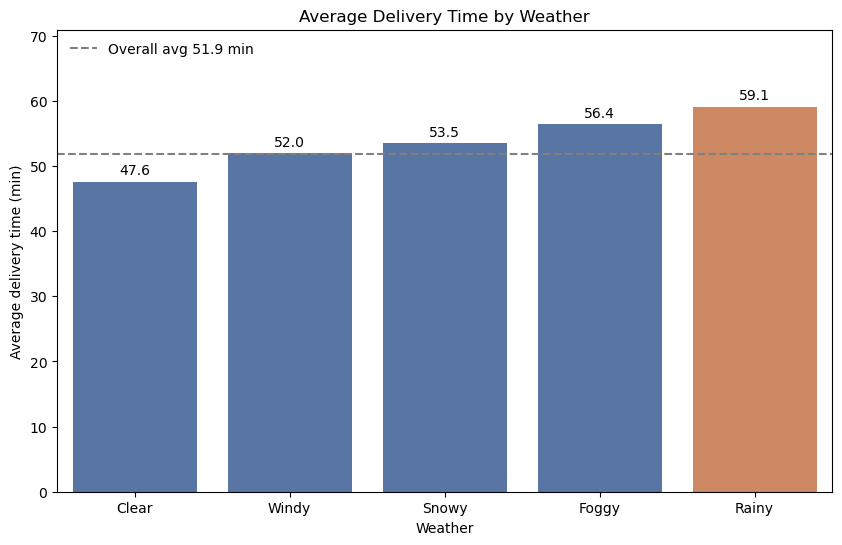

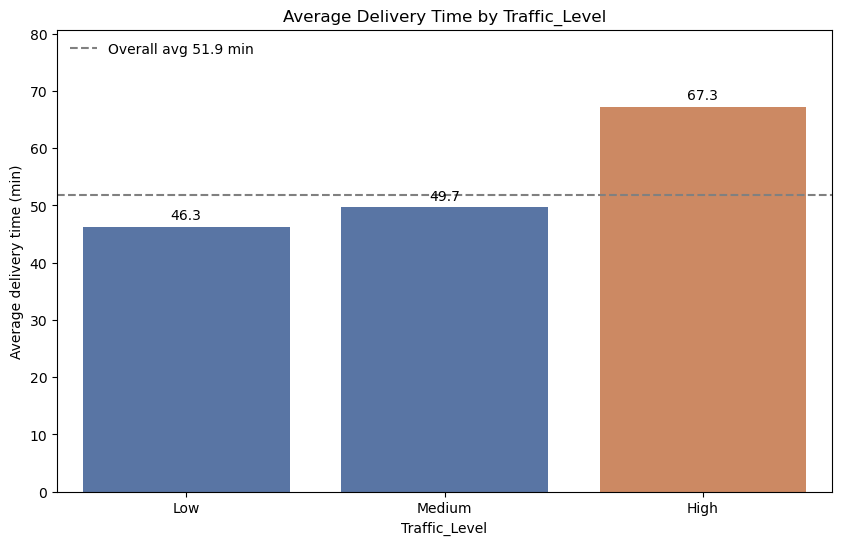

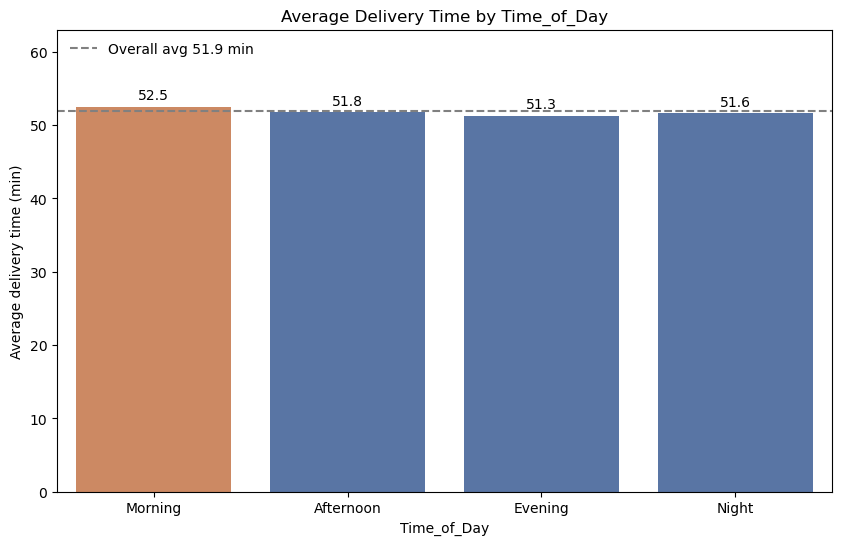

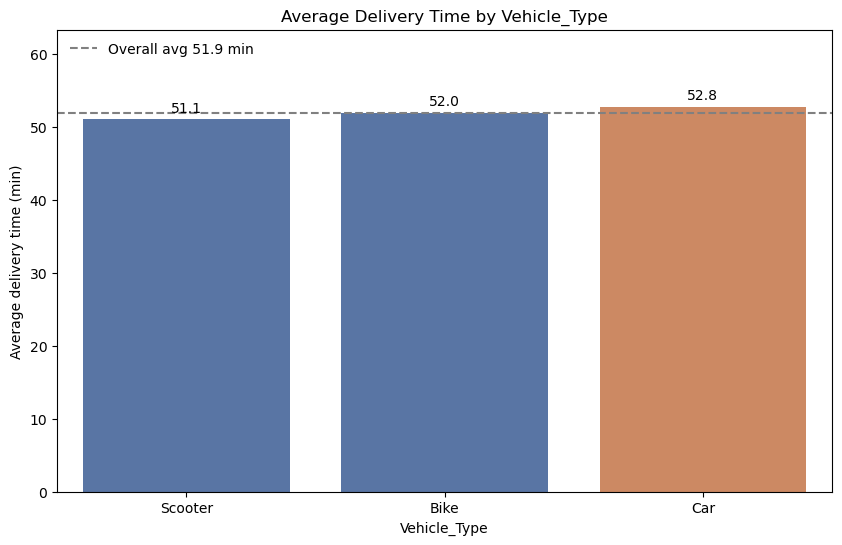

In [14]:
order_hint = {
    'Traffic_Level': ['Low', 'Medium', 'High'],
    'Time_of_Day': ['Morning', 'Afternoon', 'Evening', 'Night'],
}
overall_avg = df['Delivery_Time_min'].mean()

for col in categorical_cols:
    means = df.groupby(col)['Delivery_Time_min'].mean()
    means = means[order_hint.get(col, means.sort_values().index.tolist())]
    colors = ['#DD8452' if m == means.max() else '#4C72B0' for m in means]  # slowest group in orange

    plt.figure(figsize=(10, 6))
    ax = sns.barplot(x=means.index, y=means.values, hue=means.index, palette=colors, legend=False)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.1f', padding=3)
    plt.axhline(overall_avg, color='gray', linestyle='--', label=f'Overall avg {overall_avg:.1f} min')
    plt.ylim(0, max(means.max(), overall_avg) * 1.2)
    plt.title(f'Average Delivery Time by {col}')
    plt.xlabel(col)
    plt.ylabel('Average delivery time (min)')
    plt.legend(frameon=False, loc='upper left')
    plt.show()

**What we observed (Step 14 – Average Delivery Time by Category):**
- **Weather:** Clear is the fastest at **47.6 minutes**, then Windy (52.0), Snowy (53.5), Foggy (56.4) and Rainy (59.1), the slowest. Only Clear sits clearly below the overall average of about 51.9 minutes.
- **Traffic_Level:** Low (46.3) and Medium (49.7) are fairly close, but High traffic jumps to **67.3 minutes**, about 18 minutes more than Medium.
- **Time_of_Day** (51.3–52.5 minutes) and **Vehicle_Type** (51.1–52.8 minutes): every bar is almost as tall as the overall average line, so neither changes delivery time much on its own.

### Step 16: Pearson Correlation With the Target Variable
Here we calculate exactly how strongly each numeric feature (`Distance_km`, `Preparation_Time_min`, `Courier_Experience_yrs`) correlates with our target, `Delivery_Time_min`, and sort the results from strongest to weakest. This gives a precise, numeric way — rather than just a visual heatmap — to judge how much each numeric factor is linearly related to delivery time. Running the first cell shows `Distance_km` has by far the strongest relationship (about 0.84), `Preparation_Time_min` has a much weaker positive relationship (about 0.28), and `Courier_Experience_yrs` is essentially unrelated (about -0.04).

The second cell repeats the test with `scipy`'s `pearsonr`, which gives the correlation (`r`) **and its p-value**. Just like in the ANOVA test of Step 17, a **p-value below 0.05** means the relationship is statistically significant (very unlikely to be a coincidence). Running it shows `Distance_km` and `Preparation_Time_min` are statistically significant, while `Courier_Experience_yrs` is not (p ≈ 0.17).

Correlation with Delivery_Time_min:


Distance_km               0.844705
Preparation_Time_min      0.283938
Courier_Experience_yrs   -0.043704
Name: Delivery_Time_min, dtype: float64

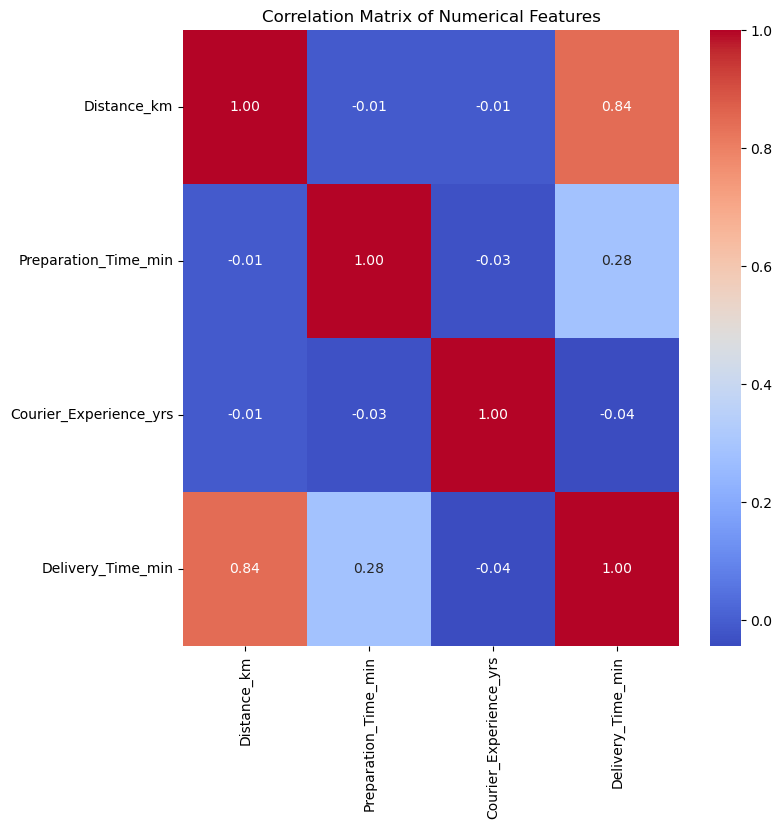

In [16]:
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
# Exclude the target variable itself from the features
if 'Delivery_Time_min' in numerical_cols:
    numerical_cols.remove('Delivery_Time_min')

print('Correlation with Delivery_Time_min:')
display(df[numerical_cols + ['Delivery_Time_min']].corr()['Delivery_Time_min'].sort_values(ascending=False).drop('Delivery_Time_min'))

plt.figure(figsize=(8, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

In [17]:
from scipy.stats import pearsonr

numeric_test_cols = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs']

pearson_results = {}
for col in numeric_test_cols:
    r_value, p_value = pearsonr(df[col], df['Delivery_Time_min'])
    pearson_results[col] = {'Correlation (r)': r_value, 'p-value': p_value}

print('\nPearson Correlation Results for Numeric Features:')
for col, results in pearson_results.items():
    print(f"{col}: r = {results['Correlation (r)']:.2f}, p-value = {results['p-value']:.4f}")
    if results['p-value'] < 0.05:
        print(f"  -> {col} is statistically significant (p < 0.05)")
    else:
        print(f"  -> {col} is not statistically significant (p >= 0.05)")


Pearson Correlation Results for Numeric Features:
Distance_km: r = 0.84, p-value = 0.0000
  -> Distance_km is statistically significant (p < 0.05)
Preparation_Time_min: r = 0.28, p-value = 0.0000
  -> Preparation_Time_min is statistically significant (p < 0.05)
Courier_Experience_yrs: r = -0.04, p-value = 0.1673
  -> Courier_Experience_yrs is not statistically significant (p >= 0.05)


### Step 17: Statistical Testing for Feature Selection — ANOVA for Categorical Features
Correlation only works on numbers, so for the category columns a different statistical test is used: **One-Way ANOVA (Analysis of Variance)**. For each category column, the code splits delivery times into groups based on category (for example, all "Rainy" deliveries vs all "Clear" deliveries) and checks whether the average delivery time genuinely differs between groups, or whether any apparent difference could just be random chance. It reports an **F-statistic** (a bigger number suggests a bigger real difference between groups) and a **p-value** (a value below 0.05 is treated as "statistically significant," meaning we're confident the effect is real and not a coincidence). Running this shows `Weather` and `Traffic_Level` are statistically significant, while `Time_of_Day` and `Vehicle_Type` are not.

In [18]:
from scipy.stats import f_oneway

categorical_cols = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']

anova_results = {}
for col in categorical_cols:
    groups = [df['Delivery_Time_min'][df[col] == category] for category in df[col].unique()]
    f_statistic, p_value = f_oneway(*groups)
    anova_results[col] = {'F-statistic': f_statistic, 'p-value': p_value}

print('\nANOVA Results for Categorical Features:')
for col, results in anova_results.items():
    print(f"{col}: F-statistic = {results['F-statistic']:.2f}, p-value = {results['p-value']:.4f}")
    if results['p-value'] < 0.05:
        print(f"  -> {col} is statistically significant (p < 0.05)")
    else:
        print(f"  -> {col} is not statistically significant (p >= 0.05)")


ANOVA Results for Categorical Features:
Weather: F-statistic = 10.47, p-value = 0.0000
  -> Weather is statistically significant (p < 0.05)
Traffic_Level: F-statistic = 61.98, p-value = 0.0000
  -> Traffic_Level is statistically significant (p < 0.05)
Time_of_Day: F-statistic = 0.15, p-value = 0.9288
  -> Time_of_Day is not statistically significant (p >= 0.05)
Vehicle_Type: F-statistic = 0.34, p-value = 0.7120
  -> Vehicle_Type is not statistically significant (p >= 0.05)


### Note: Why the Final Random Forest Still Uses All the Features
Steps 16 and 17 show that **not every column is strongly linked with the target** (`Delivery_Time_min`):
- `Courier_Experience_yrs` is **not statistically significant** in the Pearson correlation test (p ≥ 0.05, its correlation is only about -0.04).
- `Time_of_Day` and `Vehicle_Type` are **not statistically significant** in the One-Way ANOVA test (p ≥ 0.05).

We still decided to **keep all of these features in the final Random Forest model**, for these reasons:
1. **Those tests look at one feature at a time.** In real deliveries the factors work *together*. The combined comparisons in Step 15 (for example **Weather x Vehicle_Type**, or **Time_of_Day x Traffic_Level**) show effects that a one-feature-at-a-time test cannot see, such as how scooters and bikes cope with rain compared with cars. This is the same kind of comparison as *vehicle type vs. weather vs. traffic level*.
2. **A Random Forest copes well with extra features.** It automatically gives more weight to the features that help and little weight to the ones that do not, and the feature-importance chart in Step 26 shows how much each one contributes.
3. **The accuracy is already good with all features** (R² about 0.95), so there was no pressing need to remove anything.

To still give a fair comparison, **Steps 28–32 build a second model that uses only the *best* features** (the ones that pass the tests above). Both models are saved and both are offered in the web app (`app.py`): *Select all features* or *Use best features*.

### Step 15: Combined Effect of Two Factors (Heatmaps)
Factors do not always act alone. These heatmaps look at two category columns together. Each coloured cell shows the average delivery time for one combination (for example Rainy weather **and** High traffic) and `n` = the number of deliveries that average is based on. Darker red means slower deliveries.

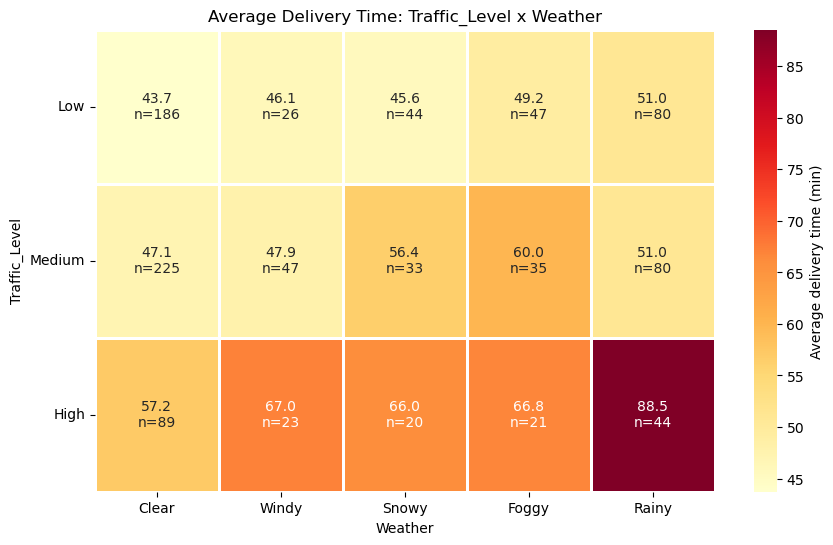

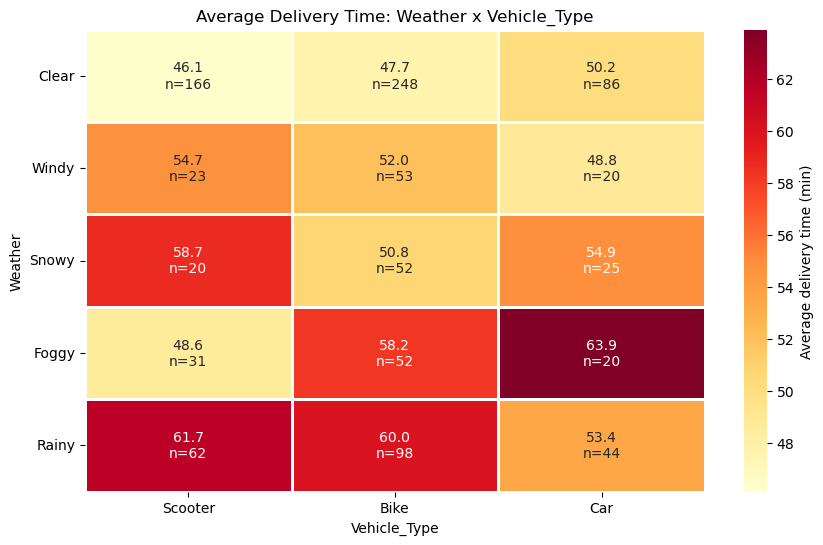

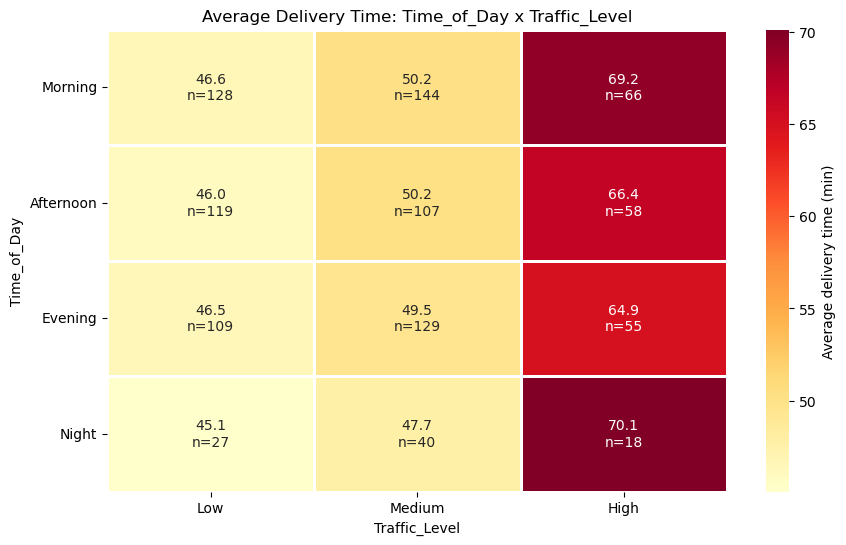

In [15]:
pairs = [('Traffic_Level', 'Weather'), ('Weather', 'Vehicle_Type'), ('Time_of_Day', 'Traffic_Level')]

def category_order(col):
    """Natural order for ordinal columns, otherwise fastest -> slowest."""
    return order_hint.get(col, df.groupby(col)['Delivery_Time_min'].mean().sort_values().index.tolist())

for row_col, col_col in pairs:
    rows, cols = category_order(row_col), category_order(col_col)
    avg = df.pivot_table(index=row_col, columns=col_col, values='Delivery_Time_min', aggfunc='mean').reindex(index=rows, columns=cols)
    cnt = df.pivot_table(index=row_col, columns=col_col, values='Delivery_Time_min', aggfunc='count').reindex(index=rows, columns=cols).fillna(0).astype(int)

    # Each cell shows the average and how many deliveries it is based on
    labels = avg.round(1).astype(str) + '\nn=' + cnt.astype(str)

    plt.figure(figsize=(10, 6))
    sns.heatmap(avg, annot=labels, fmt='', cmap='YlOrRd', linewidths=1, linecolor='white',
                cbar_kws={'label': 'Average delivery time (min)'})
    plt.title(f'Average Delivery Time: {row_col} x {col_col}')
    plt.xlabel(col_col)
    plt.ylabel(row_col)
    plt.yticks(rotation=0)
    plt.show()

**What we observed (Step 15 – Combined Effects):**
- **Traffic_Level x Weather:** the slowest combination is **High traffic + Rainy weather at 88.5 minutes** (44 deliveries), while the fastest is Low traffic + Clear weather at 43.7 minutes, a gap of about 45 minutes. Rain barely matters when traffic is Low or Medium (about 51 minutes in both cases), but it adds a lot when traffic is High, so bad weather and heavy traffic make each other worse.
- **Weather x Vehicle_Type:** Clear weather with a scooter is the fastest combination (46.1 minutes), while Foggy weather with a car is the slowest (63.9 minutes, but only 20 deliveries). In Rainy weather, scooters (61.7) and bikes (60.0) are slower than cars (53.4). Some of these cells contain only 20–25 deliveries, so treat them as hints rather than firm conclusions.
- **Time_of_Day x Traffic_Level:** within the same time of day, traffic decides the result. At night, High traffic averages 70.1 minutes compared with 45.1 minutes for Low traffic, while the time of day itself changes the averages by only a few minutes.

### Step 19: Convert Categories Into Numbers (Label Encoding)
Machine learning models can only work with numbers, not text like "Rainy" or "High". This code finds every column that still contains text values and uses Scikit-learn's `LabelEncoder` to convert each unique category into a number (for example, Clear = 0, Rainy = 1, Foggy = 2, and so on). It also prints out exactly which classes (categories) got encoded for each column, and shows the first few rows of the dataset afterward so we can see the transformation take effect.

In [20]:
from sklearn.preprocessing import LabelEncoder

# Identify categorical columns
categorical_cols = df.select_dtypes(include='object').columns

# Apply Label Encoding to each categorical column
for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    print(f"Column '{col}' encoded with classes: {le.classes_}")

print("\nDataFrame after Label Encoding:")
display(df.head())

Column 'Weather' encoded with classes: ['Clear' 'Foggy' 'Rainy' 'Snowy' 'Windy']
Column 'Traffic_Level' encoded with classes: ['High' 'Low' 'Medium']
Column 'Time_of_Day' encoded with classes: ['Afternoon' 'Evening' 'Morning' 'Night']
Column 'Vehicle_Type' encoded with classes: ['Bike' 'Car' 'Scooter']

DataFrame after Label Encoding:


,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,7.93,4,1,0,2,12,1.0,29
1,16.42,0,2,1,0,20,2.0,74
2,9.52,1,1,3,2,28,1.0,59
3,7.44,2,2,0,2,5,1.0,31
4,19.03,0,1,2,0,16,5.0,68


### Step 20: Split the Data Into Training and Testing Sets
Before training any model, the target variable (`y` = `Delivery_Time_min`, the answer we want to predict) is separated from the input features (`X` = everything else). The dataset is then split into a **training set**, used to teach the model, and a **test set**, used afterward to check how well the model performs on data it has never seen before. Here, 80% of the records go into training and 20% into testing, and `random_state=42` is fixed so the split is exactly reproducible every time this code is run.

In [21]:
from sklearn.model_selection import train_test_split

# Define target variable (y) and features (X) after encoding
y = df['Delivery_Time_min']
X = df.drop('Delivery_Time_min', axis=1)

# Perform train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (800, 7)
Shape of X_test: (200, 7)
Shape of y_train: (800,)
Shape of y_test: (200,)


### Step 21: Train a Decision Tree Regressor (Baseline Model)
This creates the first and simplest model: a **Decision Tree Regressor**. Think of it as a flowchart of yes/no questions about the input features that eventually lands on a predicted delivery time. It's trained using default settings on the training data, then used to make predictions on the test set. This model acts as our **baseline** — a simple starting point that more advanced models will be compared against.

In [22]:
from sklearn.tree import DecisionTreeRegressor

# Initialize the Decision Tree Regressor with default parameters
dtc_model = DecisionTreeRegressor(random_state=42)

# Train the model
dtc_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_dtc = dtc_model.predict(X_test)

print("Decision Tree Regressor model created and trained.")
print("Predictions on test set stored in y_pred_dtc.")

Decision Tree Regressor model created and trained.
Predictions on test set stored in y_pred_dtc.


### Step 22: Evaluate the Decision Tree's Performance
This calculates four standard metrics to judge how accurate the Decision Tree's predictions were on the test set:
- **MAE (Mean Absolute Error)** — on average, how many minutes off each prediction was.
- **MSE (Mean Squared Error)** — similar to MAE, but squares the errors first, which penalizes larger mistakes more heavily.
- **RMSE (Root Mean Squared Error)** — the square root of MSE, bringing the error back into easy-to-read minutes.
- **R² (R-squared) Score** — a score between 0 and 1 showing what percentage of the variation in delivery times the model successfully explains.

Running this cell shows the baseline Decision Tree achieves an R² of about 0.92, with an average error (MAE) of roughly 4.79 minutes.

In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred_dtc)
mse = mean_squared_error(y_test, y_pred_dtc)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_dtc)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R2) Score: {r2:.2f}")

Mean Absolute Error (MAE): 4.79
Mean Squared Error (MSE): 38.28
Root Mean Squared Error (RMSE): 6.19
R-squared (R2) Score: 0.92


### Step 23: Train a Random Forest Regressor
This trains a **Random Forest Regressor** — instead of relying on a single decision tree, a Random Forest builds many trees (100, by default) on random subsets of the data and then averages all of their predictions together. This typically produces more accurate and stable results than any single tree alone, because the mistakes of individual trees tend to cancel each other out. Just like before, it's trained on the training data and then used to predict on the test set.

> **Note:** this final model is trained on **all 7 features**, even though some of them are only weakly related to the delivery time. The reason is explained in the note right after Step 17. A second, simpler model that uses only the best features is built in Steps 28–32.

In [24]:
from sklearn.ensemble import RandomForestRegressor

# Initialize the Random Forest Regressor with default parameters
rf_model = RandomForestRegressor(random_state=42)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_rf = rf_model.predict(X_test)

print("Random Forest Regressor model created and trained.")
print("Predictions on test set stored in y_pred_rf.")

Random Forest Regressor model created and trained.
Predictions on test set stored in y_pred_rf.


### Step 24: Evaluate the Random Forest's Performance
Using the same four metrics as before (MAE, MSE, RMSE, R²), this checks how well the default Random Forest performed on the test set. Running this shows a clear improvement over the single Decision Tree — R² rises to about 0.95 and the average error (MAE) drops to about 3.72 minutes — demonstrating the benefit of combining many trees instead of relying on just one. This default Random Forest is the **final model** of this project. 

In [25]:
# Calculate evaluation metrics for the Random Forest (all features)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print(f"Mean Absolute Error (MAE): {mae_rf:.2f}")
print(f"Mean Squared Error (MSE): {mse_rf:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse_rf:.2f}")
print(f"R-squared (R2) Score: {r2_rf:.2f}")

Mean Absolute Error (MAE): 3.72
Mean Squared Error (MSE): 24.67
Root Mean Squared Error (RMSE): 4.97
R-squared (R2) Score: 0.95


### Step 26: Visualize Feature Importance of the Random Forest
This extracts the `feature_importances_` from the trained Random Forest model and plots them as a horizontal bar chart, sorted from least to most important. The top 3 drivers of delivery time are highlighted in navy, and the remaining features in amber, making it easy to see at a glance which factors matter most.

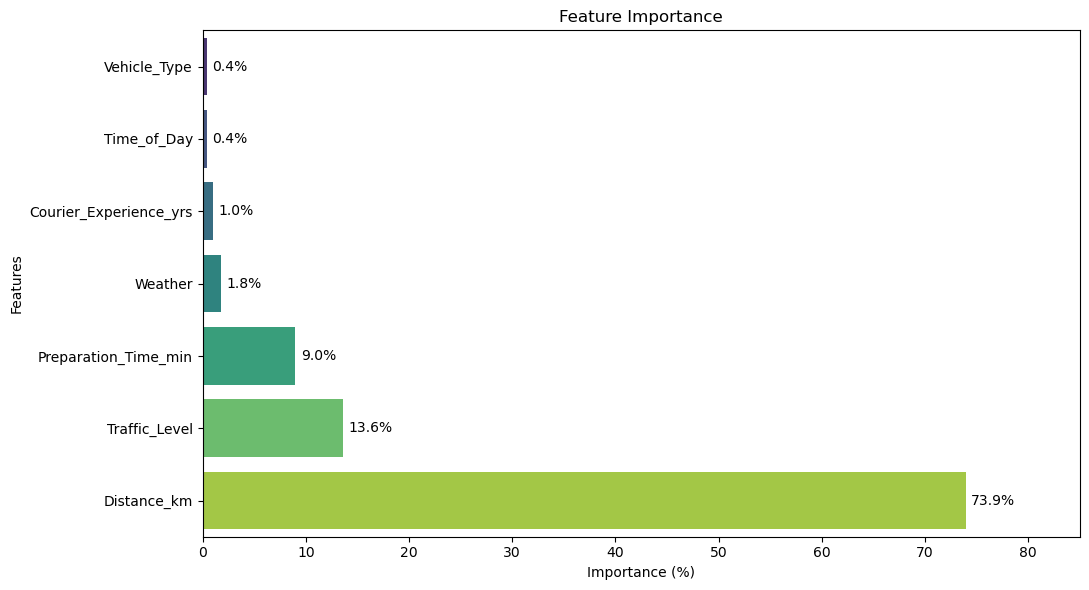

In [34]:
importances = pd.Series(rf_model.feature_importances_, index=X_train.columns) * 100
importances = importances.sort_values()

# 2. Pass figsize directly into plt.subplots()
fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(
    x=importances.values,
    y=importances.index,
    hue=importances.index,
    palette="viridis",
    legend=False,
    ax=ax,
)

# 3. Place percentage labels outside the bars
for container in ax.containers:
  ax.bar_label(container, fmt="%.1f%%", padding=4)

# 4. Add margin on the right so labels fit inside the frame
ax.set_xlim(0, importances.max() * 1.15)
ax.set_title("Feature Importance")
ax.set_xlabel("Importance (%)")
ax.set_ylabel("Features")

plt.tight_layout()
plt.show()

### Step 27: Save the Final Model and Encoders for Later Use
This last step prepares everything needed to reuse this trained model outside the notebook (for example, in a web application):
- It reloads a fresh copy of the original CSV and re-applies the exact same cleaning steps used earlier (filling missing values, dropping `Order_ID`), to make sure the encoders are built cleanly from scratch.
- It re-applies Label Encoding to the categorical columns, but this time it also keeps a dictionary of the actual `LabelEncoder` objects used for each column, so the exact same category-to-number mapping can be reused later on new input.
- It uses Python's `pickle` module to save the Random Forest model to a file called `rf_model.pkl`, and separately saves the dictionary of label encoders to `label_encoders.pkl`.

With these two files saved, the trained model can be loaded elsewhere and used to make predictions instantly, without needing to retrain it from scratch.

In [28]:
import pickle
from sklearn.preprocessing import LabelEncoder
import pandas as pd

# Re-apply Label Encoding to capture the encoders
# We need to re-create a fresh copy of the original DataFrame to ensure correct encoding without previous modifications
df_original_for_encoding = pd.read_csv("Food_Delivery_Times.csv")

# Perform the same cleaning steps as before
df_original_for_encoding['Weather'].fillna(df_original_for_encoding['Weather'].mode()[0], inplace=True)
df_original_for_encoding['Traffic_Level'].fillna(df_original_for_encoding['Traffic_Level'].mode()[0], inplace=True)
df_original_for_encoding['Time_of_Day'].fillna(df_original_for_encoding['Time_of_Day'].mode()[0], inplace=True)
df_original_for_encoding['Courier_Experience_yrs'].fillna(df_original_for_encoding['Courier_Experience_yrs'].median(), inplace=True)
df_original_for_encoding.drop('Order_ID', axis=1, inplace=True)

categorical_cols = df_original_for_encoding.select_dtypes(include='object').columns
label_encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    df_original_for_encoding[col] = le.fit_transform(df_original_for_encoding[col])
    label_encoders[col] = le
    print(f"LabelEncoder for '{col}' created and stored.")

# Save the Random Forest model
with open('rf_model.pkl', 'wb') as file:
    pickle.dump(rf_model, file)
print("Random Forest model saved as 'rf_model.pkl'")

# Save the dictionary of LabelEncoders
with open('label_encoders.pkl', 'wb') as file:
    pickle.dump(label_encoders, file)
print("LabelEncoders saved as 'label_encoders.pkl'")

LabelEncoder for 'Weather' created and stored.
LabelEncoder for 'Traffic_Level' created and stored.
LabelEncoder for 'Time_of_Day' created and stored.
LabelEncoder for 'Vehicle_Type' created and stored.
Random Forest model saved as 'rf_model.pkl'
LabelEncoders saved as 'label_encoders.pkl'


### Step 28: Select the Best Features (Statistical Tests)
The tests from Steps 16 and 17 are now turned into a clear, repeatable rule. Every feature is tested against `Delivery_Time_min`:
- **Numeric features** → Pearson correlation (`r` and its p-value).
- **Categorical features** → One-Way ANOVA (F-statistic and p-value).

A feature is a **best feature** when the **p-value of its test is below 0.05** (statistically significant), exactly as in Steps 16 and 17. Features with p ≥ 0.05 are left out. (Because the categories were label-encoded in Step 19, grouping by the code number gives exactly the same groups as grouping by the category name, so the ANOVA result is identical.)

In [29]:
from scipy.stats import pearsonr, f_oneway

numeric_features = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs']
categorical_features = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']

ALPHA = 0.05            # significance level

y_all = df['Delivery_Time_min']
rows = []
for col in X.columns:                                  # keep the same column order as the model
    if col in numeric_features:
        r, p = pearsonr(df[col], y_all)
        rows.append({'Feature': col, 'Type': 'Numeric', 'Test': 'Pearson correlation',
                     'Statistic': r, 'p-value': p})
    else:
        groups = [y_all[df[col] == code] for code in df[col].unique()]
        f_stat, p = f_oneway(*groups)
        rows.append({'Feature': col, 'Type': 'Categorical', 'Test': 'One-Way ANOVA',
                     'Statistic': f_stat, 'p-value': p})

selection_table = pd.DataFrame(rows)
selection_table['Selected'] = selection_table['p-value'] < ALPHA

# A short explanation for every feature
def explain(row):
    if row['Selected']:
        p_text = 'p < 0.0001' if row['p-value'] < 1e-4 else f"p = {row['p-value']:.4f}"
        return f"Significant ({p_text})"
    return f"Not statistically significant (p = {row['p-value']:.2f})"
selection_table['Why'] = selection_table.apply(explain, axis=1)

best_features = selection_table.loc[selection_table['Selected'], 'Feature'].tolist()

print('Feature selection results:')
display(selection_table[['Feature', 'Test', 'Statistic', 'p-value', 'Selected', 'Why']].round(4))
print('\nBest features:', best_features)
print('Not selected :', [c for c in X.columns if c not in best_features])

Feature selection results:


,Feature,Test,Statistic,p-value,Selected,Why
0,Distance_km,Pearson correlation,0.8447,0.0000,True,Significant (p < 0.0001)
1,Weather,One-Way ANOVA,10.4734,0.0000,True,Significant (p < 0.0001)
2,Traffic_Level,One-Way ANOVA,61.9765,0.0000,True,Significant (p < 0.0001)
3,Time_of_Day,One-Way ANOVA,0.1514,0.9288,False,Not statistically significant (p = 0.93)
4,Vehicle_Type,One-Way ANOVA,0.3397,0.7120,False,Not statistically significant (p = 0.71)
5,Preparation_Time_min,Pearson correlation,0.2839,0.0000,True,Significant (p < 0.0001)
6,Courier_Experience_yrs,Pearson correlation,-0.0437,0.1673,False,Not statistically significant (p = 0.17)



Best features: ['Distance_km', 'Weather', 'Traffic_Level', 'Preparation_Time_min']
Not selected : ['Time_of_Day', 'Vehicle_Type', 'Courier_Experience_yrs']


### Step 29: Train a Random Forest on the Best Features Only
This repeats Step 23, but the model only sees the **best features** chosen in Step 28. Everything else is kept exactly the same so the comparison is fair: the **same train/test split** (80/20, `random_state=42` from Step 20), the **same default settings** (100 trees, `random_state=42`) and the same test rows. The only difference is the set of input columns.

In [30]:
# Keep only the best feature columns (same rows as before)
X_train_best = X_train[best_features]
X_test_best = X_test[best_features]

# Same settings as the all-features Random Forest
rf_best_model = RandomForestRegressor(random_state=42)
rf_best_model.fit(X_train_best, y_train)

y_pred_rf_best = rf_best_model.predict(X_test_best)

print(f"Random Forest trained on {len(best_features)} best features: {best_features}")

Random Forest trained on 4 best features: ['Distance_km', 'Weather', 'Traffic_Level', 'Preparation_Time_min']


### Step 30: Evaluate the Best-Features Random Forest
The same four metrics as before (MAE, MSE, RMSE and R²) are calculated on the same test set, so the result can be compared directly with the all-features Random Forest from Step 24.

In [31]:
mae_best = mean_absolute_error(y_test, y_pred_rf_best)
mse_best = mean_squared_error(y_test, y_pred_rf_best)
rmse_best = np.sqrt(mse_best)
r2_best = r2_score(y_test, y_pred_rf_best)

print(f"Mean Absolute Error (MAE): {mae_best:.2f}")
print(f"Mean Squared Error (MSE): {mse_best:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse_best:.2f}")
print(f"R-squared (R2) Score: {r2_best:.2f}")

Mean Absolute Error (MAE): 3.56
Mean Squared Error (MSE): 21.79
Root Mean Squared Error (RMSE): 4.67
R-squared (R2) Score: 0.96


### Step 31: Compare All Three Models Side-by-Side
The summary table and bar chart from Step 25 are extended with the new model, so we can see the **Decision Tree baseline**, the **Random Forest with all features** and the **Random Forest with the best features** together. This shows whether dropping the weaker features costs any accuracy, and how much simpler the best-features model is.

Model performance comparison (all three models):


,MAE,MSE,RMSE,R2
Model,,,,
Baseline Decision Tree,4.795,38.285,6.187,0.924
Random Forest (all 7 features),3.717,24.667,4.967,0.951
Random Forest (best 4 features),3.561,21.786,4.668,0.957


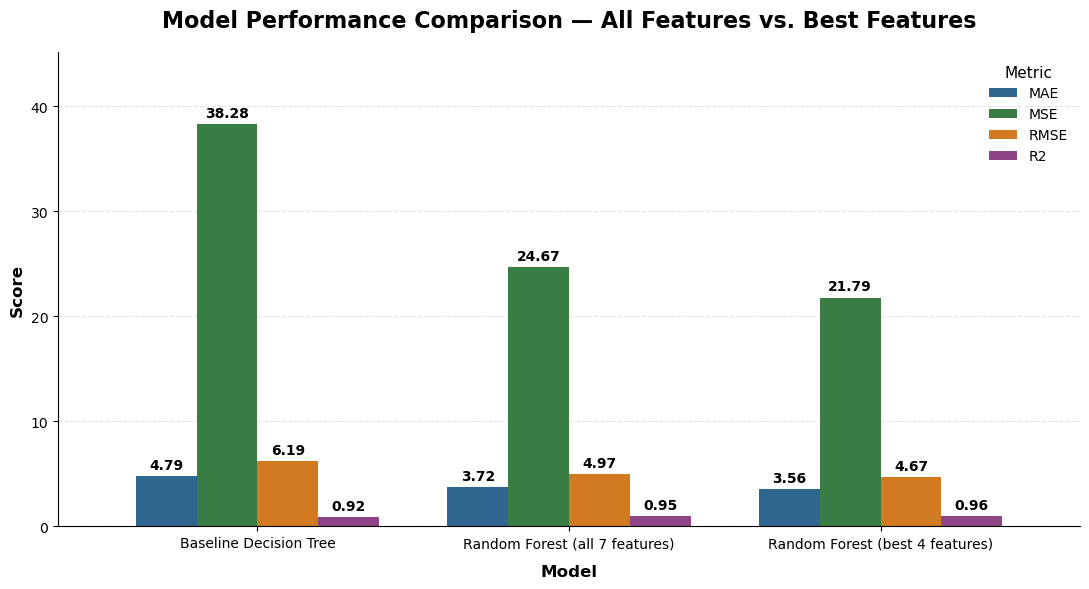

In [32]:
performance_all_df = pd.DataFrame({
    'Model': [
        'Baseline Decision Tree',
        f'Random Forest (all {X.shape[1]} features)',
        f'Random Forest (best {len(best_features)} features)'
    ],
    'MAE': [mae, mae_rf, mae_best],
    'MSE': [mse, mse_rf, mse_best],
    'RMSE': [rmse, rmse_rf, rmse_best],
    'R2': [r2, r2_rf, r2_best]
}).set_index('Model')

print('Model performance comparison (all three models):')
display(performance_all_df.round(3))

fig, ax = plt.subplots(figsize=(11, 6))
performance_all_df.plot(
    kind='bar',
    ax=ax,
    width=0.78,
    color=['#2F6690', '#3A7D44', '#D17A22', '#8E4585']
)

ax.set_title('Model Performance Comparison — All Features vs. Best Features', fontsize=16, fontweight='bold', pad=18)
ax.set_xlabel('Model', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('Score', fontsize=12, fontweight='bold')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, ha='center')
ax.legend(title='Metric', title_fontsize=11, fontsize=10, frameon=False)
ax.grid(axis='y', linestyle='--', alpha=0.35)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', label_type='edge', padding=3,
                 color='black', fontsize=10, fontweight='bold')

ax.set_ylim(0, performance_all_df.to_numpy().max() * 1.18)
fig.tight_layout()
plt.show()

### Step 32: Save the Best-Features Model for the Web App
Just like Step 27 saved the all-features model, this step saves everything the web app needs for its **"Use best features"** option:
- `rf_model_best.pkl` — the trained best-features Random Forest.
- `best_features.json` — the list of best features, the full feature-selection table (with the reason for each decision) and the accuracy of both models. The app reads this file to show the **feature summary drop-down**.

The existing `label_encoders.pkl` from Step 27 is reused, because the categories are encoded in exactly the same way. Copy the two new files into the same folder as `app.py`.

In [33]:
import json
import pickle

# Save the best-features Random Forest
with open('rf_model_best.pkl', 'wb') as file:
    pickle.dump(rf_best_model, file)
print("Best-features Random Forest saved as 'rf_model_best.pkl'")

def clean_for_json(record):
    """Convert numpy numbers / booleans to plain Python values so json can save them."""
    out = {}
    for key, value in record.items():
        if hasattr(value, 'item'):
            value = value.item()
        out[key] = value
    return out

best_importances = pd.Series(rf_best_model.feature_importances_, index=best_features).sort_values(ascending=False) * 100

best_features_info = {
    'best_features': best_features,
    'all_features': X.columns.tolist(),
    'criteria': {'alpha': ALPHA},
    'selection_table': [clean_for_json(r) for r in selection_table[
        ['Feature', 'Type', 'Test', 'Statistic', 'p-value', 'Selected', 'Why']].to_dict('records')],
    'metrics_best': {'MAE': float(mae_best), 'MSE': float(mse_best), 'RMSE': float(rmse_best), 'R2': float(r2_best)},
    'metrics_all': {'MAE': float(mae_rf), 'MSE': float(mse_rf), 'RMSE': float(rmse_rf), 'R2': float(r2_rf)},
    'importances_best': {k: float(v) for k, v in best_importances.items()},
}

with open('best_features.json', 'w', encoding='utf-8') as file:
    json.dump(best_features_info, file, indent=2)
print("Best features and summary saved as 'best_features.json'")

Best-features Random Forest saved as 'rf_model_best.pkl'
Best features and summary saved as 'best_features.json'
